# Crop Stress Detection & Irrigation Priority — Kaggle ML Notebook

**Project:** Farmer-centric Crop Stress Detection and Irrigation Priority Decision Support System for Telangana and Andhra Pradesh.

> **DATA NOTICE:** The accompanying CSV is a reproducible **synthetic demonstration dataset**, not real farm measurements or a validated agricultural dataset. Its target labels were generated from a transparent illustrative rule. Scores and metrics from this notebook demonstrate the ML pipeline only; they must not be presented as real-world accuracy or agronomic validation.

## Objectives
- Classify crop stress risk (`stress_risk`).
- Predict a continuous illustrative stress index (`stress_index_0_1`).
- Calculate a transparent rule-based irrigation priority score.
- Compare five classification and five regression algorithms.
- Tune selected models and export complete preprocessing/model pipelines.

For real deployment, replace this CSV with verified field observations and independently validated labels.


In [1]:
import os, warnings, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42


## 1. Load dataset

In Kaggle, add the uploaded dataset through **Add Input**. Update `DATA_PATH` if Kaggle assigns a different folder or filename. For local testing, the notebook also checks the current directory.


In [2]:
import glob
possible_paths = [
    "/kaggle/working/crop_stress_dataset_synthetic_demo.csv",
    "crop_stress_dataset_synthetic_demo.csv"
]
possible_paths.extend(glob.glob(
    "/kaggle/input/**/crop_stress_dataset_synthetic_demo.csv", recursive=True
))
DATA_PATH = next((p for p in possible_paths if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. In Kaggle, click Add Input and attach "
        "crop_stress_dataset_synthetic_demo.csv; then update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
display(df.info())


Shape: (5000, 28)


,field_id,observation_date,state,district,crop_type,soil_type,irrigation_method,growth_stage,soil_moisture_m3_m3,soil_temperature_c,...,nitrogen_kg_ha,phosphorus_kg_ha,potassium_kg_ha,electrical_conductivity_ds_m,irrigated_in_last_7_days,stress_index_0_1,stress_risk,irrigation_priority_score_0_100,irrigation_priority_category,data_origin
0,FIELD_0000,2025-06-01,Telangana,Rangareddy,Groundnut,Sandy,Borewell,Fruiting,0.151,24.6,...,254.2,31.2,139.3,0.92,1,0.139,Low,24.8,Low Priority,SYNTHETIC_DEMO_NOT_FIELD_MEASURED
1,FIELD_0000,2025-06-15,Telangana,Rangareddy,Groundnut,Sandy,Borewell,Flowering,0.242,32.3,...,205.7,25.5,379.5,1.14,0,0.042,Low,11.7,Low Priority,SYNTHETIC_DEMO_NOT_FIELD_MEASURED
2,FIELD_0000,2025-06-29,Telangana,Rangareddy,Groundnut,Sandy,Borewell,Vegetative,0.226,30.4,...,121.1,30.7,298.4,0.60,1,0.121,Low,20.4,Low Priority,SYNTHETIC_DEMO_NOT_FIELD_MEASURED
3,FIELD_0000,2025-07-13,Telangana,Rangareddy,Groundnut,Sandy,Borewell,Fruiting,0.241,23.1,...,282.2,30.2,214.5,0.50,0,0.192,Low,23.4,Low Priority,SYNTHETIC_DEMO_NOT_FIELD_MEASURED
4,FIELD_0000,2025-07-27,Telangana,Rangareddy,Groundnut,Sandy,Borewell,Vegetative,0.246,25.7,...,333.1,39.5,287.5,1.67,1,0.266,Moderate,28.9,Moderate Priority,SYNTHETIC_DEMO_NOT_FIELD_MEASURED


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 28 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   field_id                         5000 non-null   object 
 1   observation_date                 5000 non-null   object 
 2   state                            5000 non-null   object 
 3   district                         5000 non-null   object 
 4   crop_type                        5000 non-null   object 
 5   soil_type                        5000 non-null   object 
 6   irrigation_method                5000 non-null   object 
 7   growth_stage                     5000 non-null   object 
 8   soil_moisture_m3_m3              5000 non-null   float64
 9   soil_temperature_c               5000 non-null   float64
 10  air_temperature_c                5000 non-null   float64
 11  relative_humidity_pct            5000 non-null   float64
 12  rainfall_mm_day     

None

## 2. Data quality and exploratory analysis

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
field_id,5000,1000,FIELD_0000,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
observation_date,5000,5,2025-06-01,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,5000,2,Andhra Pradesh,2545,NaN,NaN,NaN,NaN,NaN,NaN,NaN
district,5000,14,Rangareddy,445,NaN,NaN,NaN,NaN,NaN,NaN,NaN
crop_type,5000,5,Paddy,1480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
soil_type,5000,5,Sandy,1075,NaN,NaN,NaN,NaN,NaN,NaN,NaN
irrigation_method,5000,5,Borewell,1225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
growth_stage,5000,4,Vegetative,1543,NaN,NaN,NaN,NaN,NaN,NaN,NaN
soil_moisture_m3_m3,5000.0,NaN,NaN,NaN,0.255984,0.076187,0.045,0.202,0.252,0.31,0.48
soil_temperature_c,5000.0,NaN,NaN,NaN,27.10126,3.994714,16.0,24.4,27.0,29.8,39.8


,missing_count


Duplicate rows: 0

Stress risk distribution:


stress_risk
Low         4136
Moderate     829
High          35
Name: count, dtype: int64

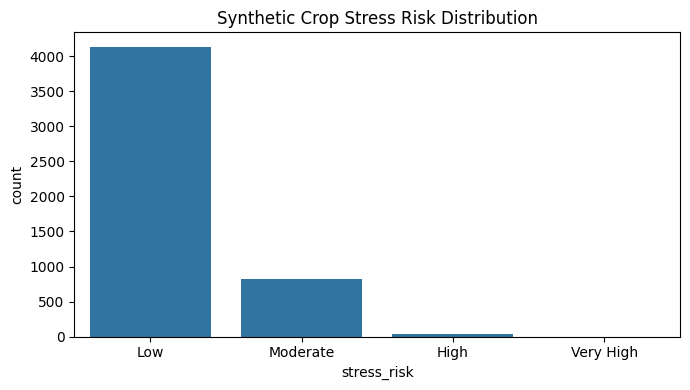

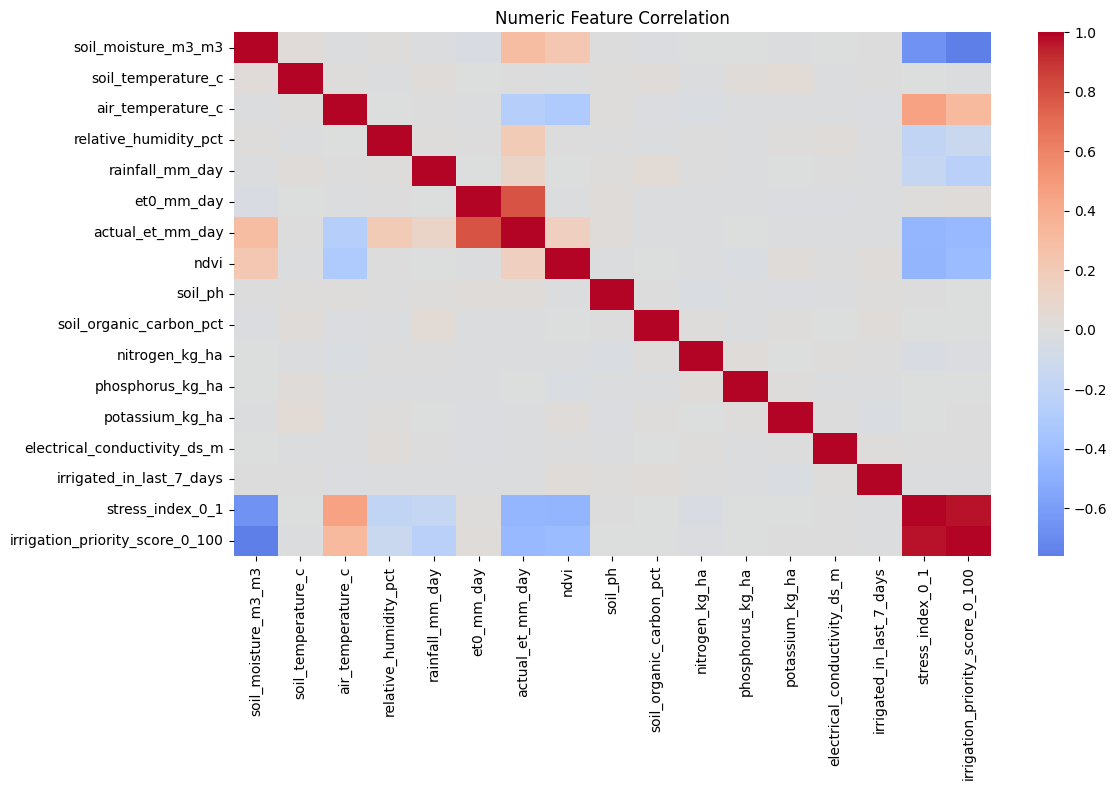

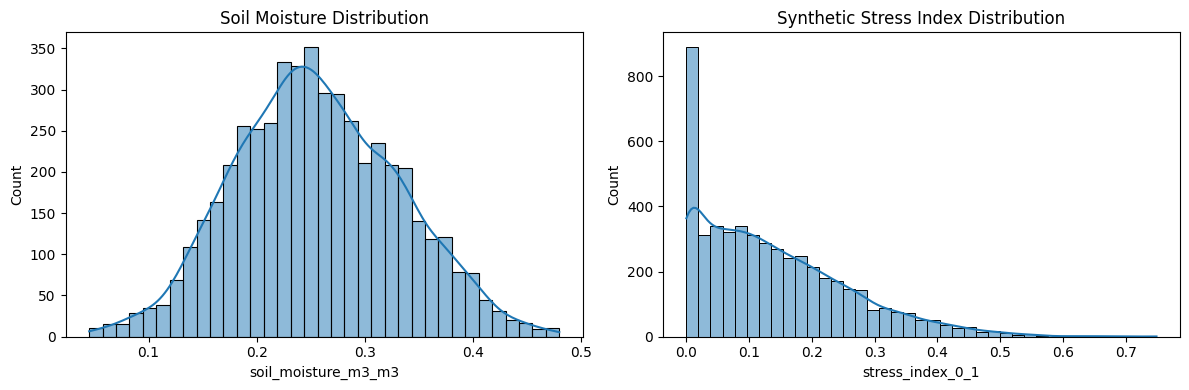

In [3]:
display(df.describe(include="all").T)
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))
print("Duplicate rows:", df.duplicated().sum())
print("\nStress risk distribution:")
display(df["stress_risk"].value_counts())

plt.figure(figsize=(7,4))
sns.countplot(data=df, x="stress_risk", order=["Low","Moderate","High","Very High"])
plt.title("Synthetic Crop Stress Risk Distribution")
plt.tight_layout()
plt.show()

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
plt.figure(figsize=(12,8))
sns.heatmap(df[numeric_cols].corr(), cmap="coolwarm", center=0)
plt.title("Numeric Feature Correlation")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(df["soil_moisture_m3_m3"], kde=True, ax=axes[0])
axes[0].set_title("Soil Moisture Distribution")
sns.histplot(df["stress_index_0_1"], kde=True, ax=axes[1])
axes[1].set_title("Synthetic Stress Index Distribution")
plt.tight_layout()
plt.show()


## 3. Define targets and prevent leakage

Identifiers, dates, target columns, the irrigation priority score/category, and the synthetic-origin marker are excluded from model inputs. `field_id` is retained only to keep all observations from a field in the same split. Group splitting reduces leakage across repeated observations of the same synthetic field.


In [4]:
TARGET_CLASS = "stress_risk"
TARGET_REG = "stress_index_0_1"
GROUP_COL = "field_id"

excluded = {
    GROUP_COL, "observation_date", "stress_risk", "stress_index_0_1",
    "irrigation_priority_score_0_100", "irrigation_priority_category",
    "data_origin"
}
feature_cols = [c for c in df.columns if c not in excluded]
X = df[feature_cols].copy()
y_class = df[TARGET_CLASS].copy()
y_reg = df[TARGET_REG].copy()
groups = df[GROUP_COL].copy()

cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y_class, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
yc_train, yc_test = y_class.iloc[train_idx], y_class.iloc[test_idx]
yr_train, yr_test = y_reg.iloc[train_idx], y_reg.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print("Train rows:", len(train_idx), "Test rows:", len(test_idx))
print("Train fields:", groups_train.nunique(), "Test fields:", groups.iloc[test_idx].nunique())
assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))
print("No field overlap between train and test.")


Train rows: 4000 Test rows: 1000
Train fields: 800 Test fields: 200
No field overlap between train and test.


## 4. Classification model comparison

All preprocessing is fitted inside each pipeline using training folds only. The test set remains held out until final evaluation.


,model,accuracy,precision_weighted,recall_weighted,f1_weighted
2,SVM,0.915,0.929945,0.915,0.918260
0,Logistic Regression,0.903,0.923215,0.903,0.909313
4,Random Forest,0.906,0.895219,0.906,0.891976
3,Decision Tree,0.864,0.861031,0.864,0.862511
1,KNN,0.878,0.858713,0.878,0.858383


Best classifier by weighted F1: SVM
              precision    recall  f1-score   support

        High       0.50      0.14      0.22         7
         Low       0.98      0.92      0.95       838
    Moderate       0.67      0.90      0.77       155

    accuracy                           0.92      1000
   macro avg       0.72      0.66      0.65      1000
weighted avg       0.93      0.92      0.92      1000



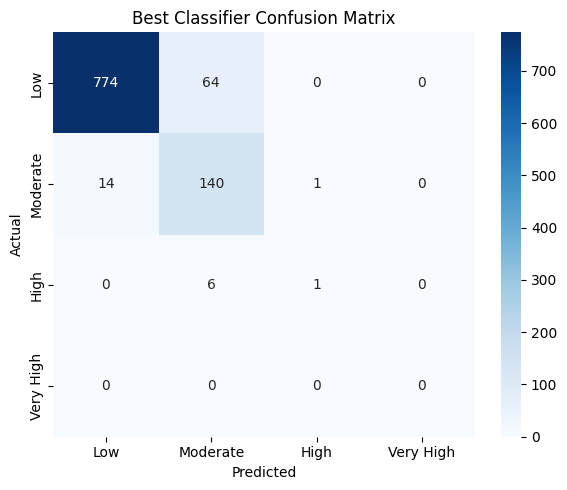

In [5]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced"),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "SVM": SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=120, class_weight="balanced",
                                            random_state=RANDOM_STATE, n_jobs=-1)
}
classification_results = []
classification_pipelines = {}

for name, estimator in classifiers.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, yc_train)
    pred = pipe.predict(X_test)
    p, r, f1, _ = precision_recall_fscore_support(
        yc_test, pred, average="weighted", zero_division=0
    )
    classification_results.append({
        "model": name, "accuracy": accuracy_score(yc_test, pred),
        "precision_weighted": p, "recall_weighted": r, "f1_weighted": f1
    })
    classification_pipelines[name] = pipe

classification_comparison = pd.DataFrame(classification_results).sort_values(
    "f1_weighted", ascending=False
)
display(classification_comparison)
best_classifier_name = classification_comparison.iloc[0]["model"]
best_classifier = classification_pipelines[best_classifier_name]
print("Best classifier by weighted F1:", best_classifier_name)
print(classification_report(yc_test, best_classifier.predict(X_test), zero_division=0))

cm = confusion_matrix(yc_test, best_classifier.predict(X_test), labels=["Low","Moderate","High","Very High"])
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Low","Moderate","High","Very High"],
            yticklabels=["Low","Moderate","High","Very High"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Best Classifier Confusion Matrix")
plt.tight_layout(); plt.show()


## 5. Regression model comparison

,model,MAE,MSE,RMSE,R2
4,Random Forest Regressor,0.037095,0.002221,0.047123,0.834570
2,SVR,0.038299,0.002330,0.048274,0.826391
0,Linear Regression,0.045799,0.003300,0.057449,0.754121
1,KNN Regressor,0.053023,0.004592,0.067767,0.657873
3,Decision Tree Regressor,0.055684,0.005230,0.072316,0.610399


Best regressor by RMSE: Random Forest Regressor


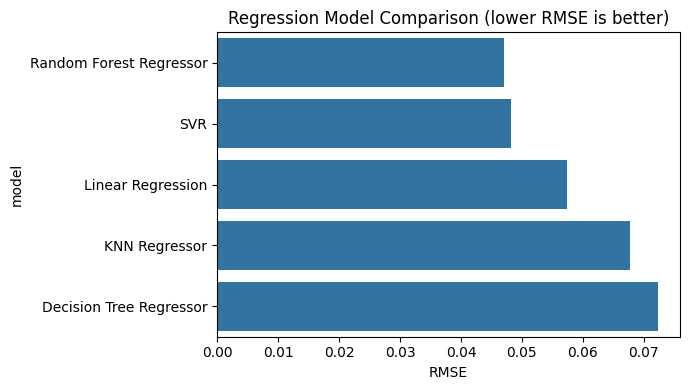

In [6]:
regressors = {
    "Linear Regression": LinearRegression(),
    "KNN Regressor": KNeighborsRegressor(n_neighbors=7),
    "SVR": SVR(C=5.0, epsilon=0.05),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=120, random_state=RANDOM_STATE, n_jobs=-1)
}
regression_results = []
regression_pipelines = {}

for name, estimator in regressors.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, yr_train)
    pred = pipe.predict(X_test)
    regression_results.append({
        "model": name,
        "MAE": mean_absolute_error(yr_test, pred),
        "MSE": mean_squared_error(yr_test, pred),
        "RMSE": np.sqrt(mean_squared_error(yr_test, pred)),
        "R2": r2_score(yr_test, pred)
    })
    regression_pipelines[name] = pipe

regression_comparison = pd.DataFrame(regression_results).sort_values("RMSE")
display(regression_comparison)
best_regressor_name = regression_comparison.iloc[0]["model"]
best_regressor = regression_pipelines[best_regressor_name]
print("Best regressor by RMSE:", best_regressor_name)

plt.figure(figsize=(7,4))
sns.barplot(data=regression_comparison, x="RMSE", y="model")
plt.title("Regression Model Comparison (lower RMSE is better)")
plt.tight_layout(); plt.show()


## 6. Hyperparameter tuning

Use GroupKFold so repeated observations from one field are not split across training and validation folds. Tune the leading Random Forest candidates as a bounded, Kaggle-friendly example. If the selected baseline model is not Random Forest, the baseline comparison remains available and the tuned RF is evaluated separately.


In [7]:
n_splits = min(3, groups_train.nunique())
cv = GroupKFold(n_splits=n_splits)

clf_tune_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1))
])
clf_grid = {
    "model__n_estimators": [80],
    "model__max_depth": [None, 12],
    "model__min_samples_leaf": [1, 3]
}
clf_search = GridSearchCV(clf_tune_pipe, clf_grid, cv=cv, scoring="f1_weighted",
                          n_jobs=1, refit=True)
clf_search.fit(X_train, yc_train, groups=groups_train)
tuned_classifier = clf_search.best_estimator_
print("Classifier best params:", clf_search.best_params_)
print("Tuned classifier test F1:",
      precision_recall_fscore_support(yc_test, tuned_classifier.predict(X_test),
                                      average="weighted", zero_division=0)[2])

reg_tune_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
])
reg_grid = {
    "model__n_estimators": [80],
    "model__max_depth": [None, 12],
    "model__min_samples_leaf": [1, 3]
}
reg_search = GridSearchCV(reg_tune_pipe, reg_grid, cv=cv, scoring="neg_root_mean_squared_error",
                          n_jobs=1, refit=True)
reg_search.fit(X_train, yr_train, groups=groups_train)
tuned_regressor = reg_search.best_estimator_
print("Regressor best params:", reg_search.best_params_)
print("Tuned regressor test RMSE:",
      np.sqrt(mean_squared_error(yr_test, tuned_regressor.predict(X_test))))


Classifier best params: {'model__max_depth': 12, 'model__min_samples_leaf': 3, 'model__n_estimators': 80}
Tuned classifier test F1: 0.9097113115402541
Regressor best params: {'model__max_depth': 12, 'model__min_samples_leaf': 3, 'model__n_estimators': 80}
Tuned regressor test RMSE: 0.047688188051568034


## 7. Irrigation priority decision support

The priority score is calculated by a transparent illustrative rule, not a separately trained model and not a validated irrigation prescription. It is deliberately not used as an input feature.


In [8]:
def calculate_irrigation_priority(data, predicted_stress_index):
    moisture_deficit = np.clip((0.27 - data["soil_moisture_m3_m3"].to_numpy()) / 0.22, 0, 1)
    rainfall_relief = np.clip(data["rainfall_mm_day"].to_numpy() / 18, 0, 1)
    score = np.clip(
        100 * (0.72 * np.clip(predicted_stress_index, 0, 1)
               + 0.20 * moisture_deficit
               + 0.08 * (1 - rainfall_relief)), 0, 100
    )
    category = pd.cut(score, bins=[-0.001,25,50,75,100.001],
                      labels=["Low Priority","Moderate Priority","High Priority","Critical Priority"])
    return np.round(score, 1), category.astype(str)

predicted_stress = np.clip(tuned_regressor.predict(X_test), 0, 1)
priority_scores, priority_categories = calculate_irrigation_priority(X_test, predicted_stress)

sample_results = pd.DataFrame({
    "actual_stress_risk": yc_test.values,
    "predicted_stress_risk": tuned_classifier.predict(X_test),
    "actual_stress_index": yr_test.values,
    "predicted_stress_index": np.round(predicted_stress, 3),
    "irrigation_priority_score": priority_scores,
    "irrigation_priority_category": priority_categories
}, index=X_test.index)
display(sample_results.head(10))


,actual_stress_risk,predicted_stress_risk,actual_stress_index,predicted_stress_index,irrigation_priority_score,irrigation_priority_category
50,Low,Low,0.000,0.012,5.1,Low Priority
51,Low,Low,0.063,0.039,9.7,Low Priority
52,Low,Low,0.000,0.007,5.2,Low Priority
53,Low,Low,0.088,0.035,9.8,Low Priority
54,Low,Low,0.000,0.007,4.4,Low Priority
115,Moderate,Low,0.265,0.159,18.7,Low Priority
116,Moderate,Moderate,0.293,0.291,35.3,Moderate Priority
117,Moderate,Moderate,0.299,0.275,37.4,Moderate Priority
118,Low,Low,0.101,0.116,21.1,Low Priority
119,Low,Low,0.183,0.249,35.5,Moderate Priority


## 8. Save comparison reports and trained pipelines

In [9]:
OUTPUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
classification_comparison.to_csv(os.path.join(OUTPUT_DIR, "classification_comparison.csv"), index=False)
regression_comparison.to_csv(os.path.join(OUTPUT_DIR, "regression_comparison.csv"), index=False)

bundle = {
    "classification_pipeline": tuned_classifier,
    "regression_pipeline": tuned_regressor,
    "feature_columns": feature_cols,
    "categorical_columns": cat_cols,
    "numerical_columns": num_cols,
    "classification_labels": ["Low", "Moderate", "High", "Very High"],
    "classification_metrics": classification_comparison.to_dict(orient="records"),
    "regression_metrics": regression_comparison.to_dict(orient="records"),
    "classifier_best_params": clf_search.best_params_,
    "regressor_best_params": reg_search.best_params_,
    "priority_method": "Illustrative rule: 72% predicted stress + 20% moisture deficit + 8% rainfall relief",
    "dataset_notice": "Synthetic demonstration data; not field-validated",
    "random_state": RANDOM_STATE
}
model_path = os.path.join(OUTPUT_DIR, "crop_stress_models.joblib")
joblib.dump(bundle, model_path)
print("Saved:", model_path)
print("Saved comparison CSV files.")


Saved: .\crop_stress_models.joblib
Saved comparison CSV files.


## 9. Reload and verify artifact

In [10]:
loaded = joblib.load(model_path)
assert loaded["classification_pipeline"] is not None
assert loaded["regression_pipeline"] is not None
one_row = X_test.iloc[[0]]
class_prediction = loaded["classification_pipeline"].predict(one_row)[0]
stress_prediction = float(np.clip(loaded["regression_pipeline"].predict(one_row)[0], 0, 1))
one_priority, one_category = calculate_irrigation_priority(one_row, np.array([stress_prediction]))
print({
    "predicted_stress_risk": class_prediction,
    "predicted_stress_index": round(stress_prediction, 3),
    "irrigation_priority_score": float(one_priority[0]),
    "irrigation_priority_category": one_category[0]
})


{'predicted_stress_risk': 'Low', 'predicted_stress_index': 0.012, 'irrigation_priority_score': 5.1, 'irrigation_priority_category': 'Low Priority'}


## 10. Conclusion, limitations and next steps

This notebook demonstrates a complete supervised-learning workflow using a **synthetic demonstration dataset**. Its metrics measure how well models learn the synthetic label-generation process; they do not establish performance on real farms.

Before real farmer use:
1. Replace the synthetic CSV with verified, representative field observations.
2. Obtain independently assessed crop-stress labels and irrigation outcomes.
3. Validate by district, crop, season and unseen farms.
4. Confirm feature availability and sensor/API provenance at inference time.
5. Have agronomists validate irrigation recommendations.
6. Monitor model drift and recalibrate using real observations.

**Kaggle publishing:** Add the CSV as a Kaggle Dataset input, run all cells, confirm the model and comparison files appear in `/kaggle/working/`, then Save Version and publish the notebook with Public visibility if your account permits.
